# EDA and preprocessing study: Simplified MM-IMDb (poster + plot → 23 genres)

**Project 2.2: individual implementation (Anh Khoa Le) of the Group 18 proposal.** This notebook is the data-quality assessment and the evidence behind every preprocessing step in
`scripts/01_preprocess.py`, `02_featurise.py` and `03_ablation.py`. It follows the proposal (Project 2.1):
CLIP ViT-B/32 for posters, DistilBERT (256 tokens) for plots, a 60/10/30 split without cross-split duplicate groups,
and macro-F1 as the primary metric.

Run order: `01_preprocess.py` → `02_featurise.py` → `03_ablation.py` → this notebook (§9–10 read their outputs).

| § | Question | Decision it drives |
|---|---|---|
| 1 | What is in the files? Are the modalities aligned row by row? | loaders, genre order |
| 2 | Are the images stored correctly? | `decode()`: storage bug fixed |
| 3 | How imbalanced and correlated are the labels? | stratified split, macro-F1, per-genre thresholds |
| 4 | What does the text look like, and what should cleaning do? | detokenisation, number masking, stop / redundant words |
| 5 | What do posters look like? Crop or letterbox? | CLIP preprocessing choice, grayscale bias audit |
| 6 | Duplicates and label noise? | grouped split, exclusions |
| 7 | Is the 60/10/30 split sound? | leakage check |
| 8 | Do poster and plot actually describe the same movie? | cross-modal alignment check |
| 9 | Which cleaning and crop choices win on validation? | final preprocessing |
| 10 | Do the modalities carry complementary signal? | motivation for fusion |

In [1]:
import sys, json, re
from collections import Counter
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from mmfusion.config import GENRES, SPLITS, FEAT, DATA, RESULTS, TEXT_VARIANTS, DISTIL_NAME
from mmfusion.data import load_table, images_memmap, decode
from mmfusion import preprocess as pp
sns.set_theme(style="whitegrid", context="notebook"); plt.rcParams.update({"figure.dpi": 100})
idx, Y, texts = load_table(); mm = images_memmap(); N = len(Y)
meta = pd.read_csv(SPLITS / "meta.csv"); S = json.load(open(SPLITS / "preprocess_summary.json"))
V = {v: json.load(open(SPLITS / "texts" / f"{v}.json")) for v in TEXT_VARIANTS}
tr, va, te = (np.flatnonzero(meta.split == s) for s in (0, 1, 2))
print(f"{N:,} movies | images {mm.shape} {mm.dtype} | labels {Y.shape} | texts {len(texts):,}")
print(f"image_index == row id for every row: {(idx == np.arange(N)).all()}  -> poster i belongs to plot i")
print(f"data.npy {(DATA/'data.npy').stat().st_size/1e6:.1f} MB, images.npz {(DATA/'images.npz').stat().st_size/1e9:.2f} GB")

25,959 movies | images (25959, 3, 256, 160) uint8 | labels (25959, 23) | texts 25,959
image_index == row id for every row: True  -> poster i belongs to plot i
data.npy 18.1 MB, images.npz 3.19 GB


## 1. Files, schema and row alignment
`data.npy` is an object array `[image_index, one_hot(23), plot_text]`. Its `image_index` equals the row number for all 25,959 rows
and the image array has exactly 25,959 posters, so modality pairing is by row (the alignment *content* check is §8).
The genre column order is **not shipped**. We recovered it by matching column sums to the frequency table of Arevalo et al. (2017), Table 1:

In [2]:
paper = {"Drama": 13967, "Comedy": 8592, "Romance": 5364, "Thriller": 5192, "Crime": 3838, "Action": 3550, "Adventure": 2710,
         "Horror": 2703, "Documentary": 2082, "Mystery": 2057, "Sci-Fi": 1991, "Fantasy": 1933, "Family": 1668, "Biography": 1343,
         "War": 1335, "History": 1143, "Music": 1045, "Animation": 997, "Musical": 841, "Western": 705, "Sport": 634,
         "Short": 471, "Film-Noir": 338}
chk = pd.DataFrame({"count in file": Y.sum(0), "Arevalo et al. (2017)": [paper[g] for g in GENRES]}, index=GENRES)
print("all 23 counts match:", (chk.iloc[:, 0] == chk.iloc[:, 1]).all()); chk.T

all 23 counts match: True


,Drama,Comedy,Romance,Thriller,Crime,Action,Adventure,Horror,Documentary,Mystery,...,Biography,War,History,Music,Animation,Musical,Western,Sport,Short,Film-Noir
count in file,13967,8592,5364,5192,3838,3550,2710,2703,2082,2057,...,1343,1335,1143,1045,997,841,705,634,471,338
Arevalo et al. (2017),13967,8592,5364,5192,3838,3550,2710,2703,2082,2057,...,1343,1335,1143,1045,997,841,705,634,471,338


## 2. Image encoding: a silent storage bug
Each poster was stored as **BGR − Caffe ImageNet mean**, then cast to `uint8`, so negative values wrapped around (top row below).
`decode()` adds the mean back modulo 256 and swaps BGR→RGB. A neighbour-pixel smoothness test confirms the fix.

neighbour-pixel jumps > 128 grey levels: stored 5.85% vs decoded 1.04%


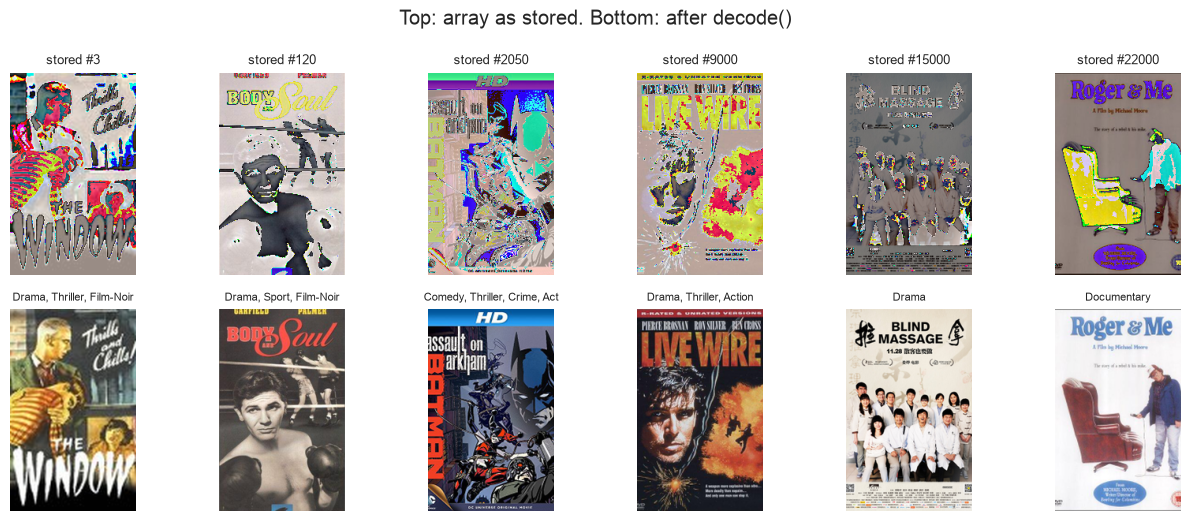

In [3]:
pick = [3, 120, 2050, 9000, 15000, 22000]
raw = np.asarray(mm[pick]); dec = decode(raw)
fig, ax = plt.subplots(2, 6, figsize=(13, 5.3))
for k, i in enumerate(pick):
    ax[0, k].imshow(np.moveaxis(raw[k], 0, -1)); ax[0, k].axis("off"); ax[0, k].set_title(f"stored #{i}", fontsize=9)
    ax[1, k].imshow(dec[k]); ax[1, k].axis("off"); ax[1, k].set_title(", ".join(GENRES[g] for g in np.flatnonzero(Y[i]))[:28], fontsize=8)
fig.suptitle("Top: array as stored. Bottom: after decode()"); plt.tight_layout()
s = np.asarray(mm[:500]).astype(int); d = np.moveaxis(decode(np.asarray(mm[:500])), -1, 1).astype(int)
print(f"neighbour-pixel jumps > 128 grey levels: stored {(np.abs(np.diff(s, axis=-1)) > 128).mean():.2%} vs decoded {(np.abs(np.diff(d, axis=-1)) > 128).mean():.2%}")

## 3. Labels: imbalance, cardinality, co-occurrence

mean 2.48 genres/movie | multi-label share 77.0% | 2,218 distinct label sets, 1,104 seen once


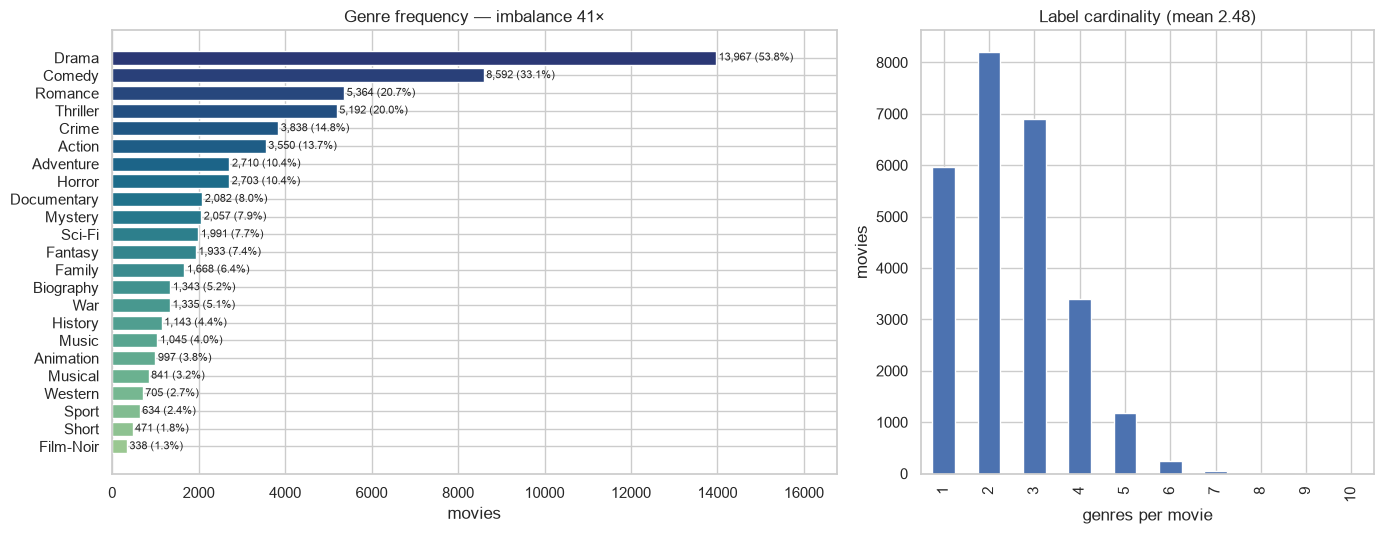

In [4]:
cnt = pd.Series(Y.sum(0), index=GENRES).sort_values(); card = Y.sum(1)
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1.6, 1]})
ax[0].barh(cnt.index, cnt.values, color=sns.color_palette("crest", 23))
for i, v in enumerate(cnt.values): ax[0].text(v + 60, i, f"{v:,} ({v/N:.1%})", va="center", fontsize=8)
ax[0].set_xlim(0, cnt.max() * 1.2); ax[0].set_xlabel("movies"); ax[0].set_title(f"Genre frequency — imbalance {cnt.max()/cnt.min():.0f}×")
pd.Series(card).value_counts().sort_index().plot.bar(ax=ax[1], color="#4C72B0")
ax[1].set_xlabel("genres per movie"); ax[1].set_ylabel("movies"); ax[1].set_title(f"Label cardinality (mean {card.mean():.2f})")
plt.tight_layout()
sets = Counter(tuple(np.flatnonzero(r)) for r in Y)
print(f"mean {card.mean():.2f} genres/movie | multi-label share {(card > 1).mean():.1%} | {len(sets):,} distinct label sets, {sum(v == 1 for v in sets.values()):,} seen once")

strongest positive pairs: [('Animation', 'Short', 10.2), ('Family', 'Animation', 8.9), ('War', 'History', 6.2), ('Biography', 'History', 5.7), ('Fantasy', 'Animation', 5.1), ('Crime', 'Film-Noir', 4.8)]


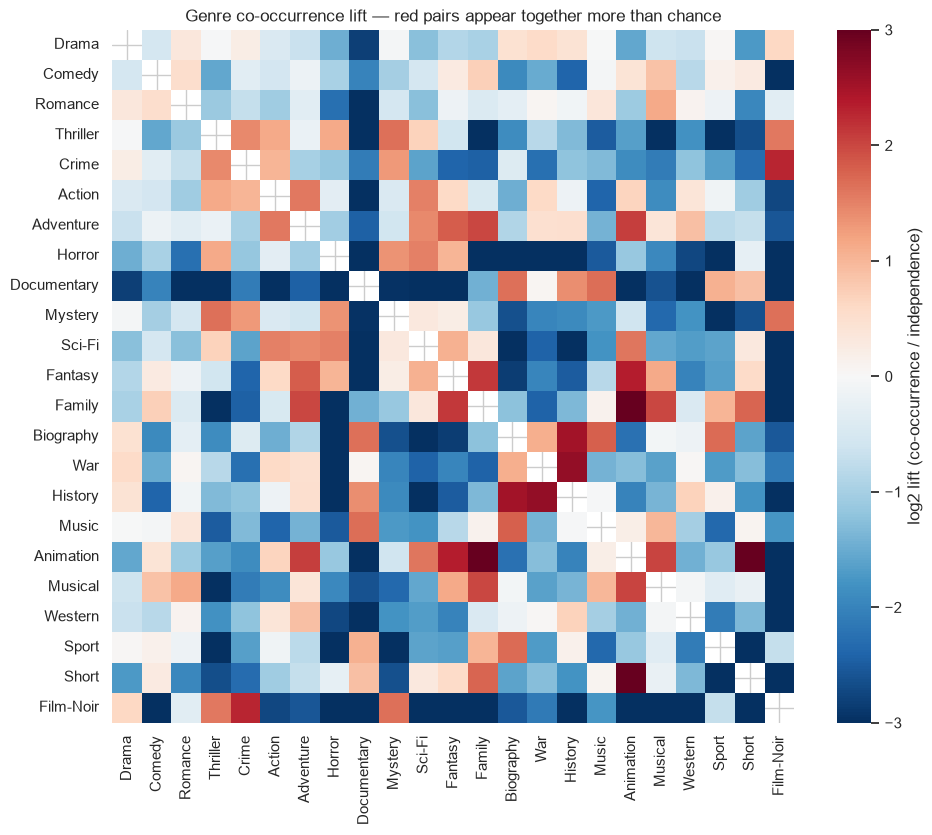

In [5]:
P = Y.mean(0); co = (Y.T.astype(float) @ Y) / N; lift = co / np.outer(P, P); np.fill_diagonal(lift, np.nan); order = np.argsort(-P)
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(np.log2(np.maximum(lift[np.ix_(order, order)], 1/8)), cmap="RdBu_r", center=0, vmin=-3, vmax=3, ax=ax,
            xticklabels=np.array(GENRES)[order], yticklabels=np.array(GENRES)[order], cbar_kws={"label": "log2 lift (co-occurrence / independence)"})
ax.set_title("Genre co-occurrence lift — red pairs appear together more than chance")
pairs = [(GENRES[a], GENRES[b], round(float(lift[a, b]), 1)) for a in range(23) for b in range(a + 1, 23) if co[a, b] * N >= 50]
print("strongest positive pairs:", sorted(pairs, key=lambda x: -x[2])[:6])

**Implications.** The 41× imbalance (Drama 54% vs Film-Noir 1.3%) is why the proposal makes **macro-F1** primary and why we tune a
**decision threshold per genre** on validation. There are 2,218 label sets, half seen once, so independent sigmoid outputs are used, not a label powerset.

## 4. Text modality: what cleaning is needed?
### 4a. Length and the 256-token window

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (556 > 512). Running this sequence through the model will result in indexing errors


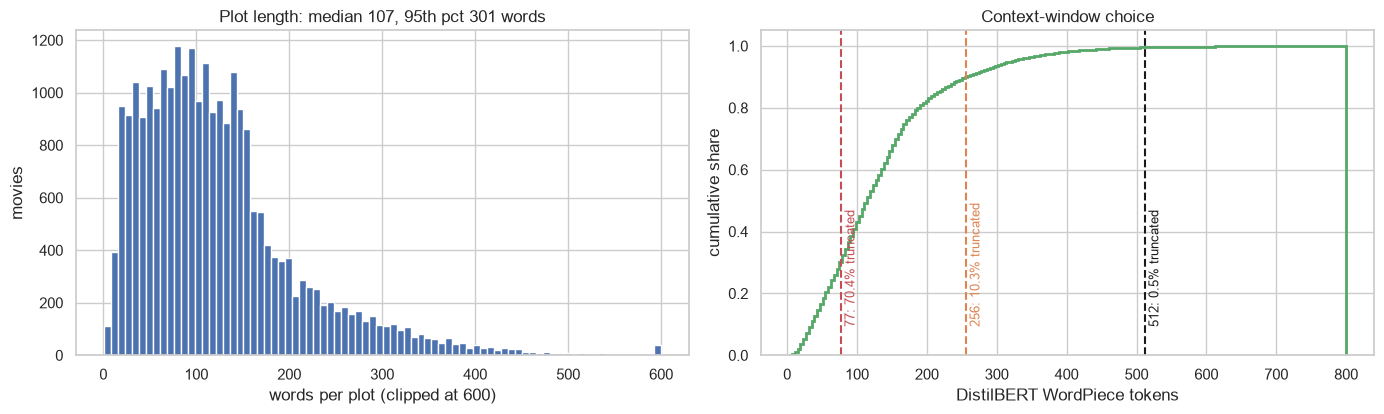

In [6]:
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained(DISTIL_NAME)
ntok = np.array([len(x) for x in tok(V["detok_num"])["input_ids"]])
words = meta.n_words.values
fig, ax = plt.subplots(1, 2, figsize=(14, 4.3))
ax[0].hist(np.clip(words, 0, 600), 80, color="#4C72B0"); ax[0].set_xlabel("words per plot (clipped at 600)"); ax[0].set_ylabel("movies")
ax[0].set_title(f"Plot length: median {np.median(words):.0f}, 95th pct {np.percentile(words, 95):.0f} words")
ax[1].hist(np.clip(ntok, 0, 800), 200, color="#55A868", cumulative=True, density=True, histtype="step", lw=2)
for L, c in [(77, "#C44E52"), (256, "#DD8452"), (512, "k")]:
    ax[1].axvline(L, color=c, ls="--"); ax[1].text(L + 5, .1, f"{L}: {(ntok > L).mean():.1%} truncated", color=c, rotation=90, fontsize=9)
ax[1].set_xlabel("DistilBERT WordPiece tokens"); ax[1].set_ylabel("cumulative share"); ax[1].set_title("Context-window choice")
plt.tight_layout()

### 4b. Artefacts left by the dataset authors
The plots were pre-tokenised: lower-cased, punctuation split off (`ex - partner ' s`), and **every digit run replaced by `N`**.
The numbers are therefore already masked at source; what remains is to decide how the placeholder is represented.

In [7]:
pat = {"standalone N": r"\bN\b", "(N) year aside": r"\(\s*N\s*\)", "(N - N) range": r"\(\s*N\s*-\s*N\s*\)",
       "N - year - old": r"\bN\s*-\s*year\s*-\s*old", "the N s (decade)": r"\bthe N s\b", "split clitic  ' s": r" ' s\b",
       "spaced punctuation ' , '": r" , ", "ellipsis . . .": r"\.\s\.\s\.", "parenthetical aside": r"\([^()]{1,40}\)"}
art = pd.DataFrame({"docs with pattern": {k: int(np.sum([bool(re.search(p, t)) for t in texts])) for k, p in pat.items()},
                    "occurrences": {k: int(sum(len(re.findall(p, t)) for t in texts)) for k, p in pat.items()}})
art["share of docs"] = (art["docs with pattern"] / N).map("{:.1%}".format); display(art)
par = Counter(m.strip() for t in texts for m in re.findall(r"\(([^()]{1,40})\)", t))
print("most common parenthetical asides:", par.most_common(15))

,docs with pattern,occurrences,share of docs
standalone N,7281,12280,28.0%
(N) year aside,85,172,0.3%
(N - N) range,63,70,0.2%
N - year - old,415,453,1.6%
the N s (decade),335,358,1.3%
split clitic ' s,14076,30571,54.2%
"spaced punctuation ' , '",23567,162683,90.8%
ellipsis . . .,1828,2218,7.0%
parenthetical aside,3133,5371,12.1%


most common parenthetical asides: [('N', 172), ('N - N', 70), ('N -', 15), ('dolph lundgren', 12), ('literally', 8), ('s', 8), ('shahrukh khan', 6), ('?', 5), ('korean with english subtitles', 5), ('amitabh bachchan', 5), ('i', 4), ('bruce willis', 4), ('!', 4), ('jean - claude van damme', 4), ('roberts', 4)]


Parenthetical asides are mostly **masked years** (`(N)`, `(N - N)`), which carry nothing once digits are gone, and **cast names**
(`(dolph lundgren)`, `(shahrukh khan)`). Cast names are kept: removing them would need a name recogniser, and they are a known
leakage path (an actor strongly tied to one genre), which we flag in the bias discussion instead.

### 4c. The cleaning variants
Each step is a separate function in `mmfusion/preprocess.py`, so it can be ablated:

| variant | adds | intended for |
|---|---|---|
| `raw` | text as shipped | reference |
| `detok` | re-join clitics/hyphens/punctuation, normalise ellipses and quotes | contextual encoders (pretrained on natural text) |
| `detok_num` | drop `(N)` / `(N - N)` year asides, map `N` → `#` (one WordPiece token) | all models |
| `detok_num_stop` | remove English stop words (negations *no, not, never…* kept) | bag-of-words models |
| `detok_num_stop_domain` | remove *corpus-redundant* words learned on train (below) | bag-of-words models |

In [8]:
for i in (0, 2, 7):
    print(f"--- movie #{i}")
    for v in TEXT_VARIANTS: print(f"{v:22s} {V[v][i][:170]}")
vs = pd.DataFrame(json.load(open(SPLITS / "text_variant_stats.json"))).T.drop(columns="example")
vs.round(3)

--- movie #0
raw                    sardonic detective shane , thrown out of one town for bringing trouble , heads for home and his ex - partner ' s detective agency . the business is in a sad way , and sha
detok                  sardonic detective shane, thrown out of one town for bringing trouble, heads for home and his ex-partner's detective agency. the business is in a sad way, and shane, who 
detok_num              sardonic detective shane, thrown out of one town for bringing trouble, heads for home and his ex-partner's detective agency. the business is in a sad way, and shane, who 
detok_num_stop         sardonic detective shane, thrown town bringing trouble, heads home ex-partner's detective agency. business sad way, shane, forethought provide #-dollar commission old lad
detok_num_stop_domain  sardonic detective shane, thrown town bringing trouble, heads home ex-partner's detective agency. business sad way, shane, forethought provide #-dollar commission old lad
--- movie #2
raw 

,mean_words,vocab_size,mean_distilbert_tokens,median_distilbert_tokens,share_truncated_at_256,share_truncated_at_512,share_with_N_or_mask
raw,124.412766,69921,135.285643,116.0,0.102777,0.004738,0.280481
detok,106.46897,89443,135.277746,116.0,0.102739,0.004738,0.177318
detok_num,106.428445,89449,135.244385,116.0,0.1027,0.0047,0.277938
detok_num_stop,55.382912,89153,84.172156,72.0,0.015447,0.000539,0.277938
detok_num_stop_domain,54.119535,89074,82.90458,71.0,0.013868,0.000539,0.277938


Stop-word removal halves the plot length (≈106 → 55 words) and cuts the share of plots truncated at 256 DistilBERT tokens
from about 10% to 1.5%. That is a genuine trade-off for a 256-token encoder: more of each plot fits, but grammar and negation
context are lost. §9 measures which effect wins.

### 4d. Which words are actually redundant? Mutual information with the genre labels
"Redundant" is defined from the data, not a fixed list: for every word in ≥1% of **training** plots we compute the mutual
information between *word present* and each genre, summed over the 23 genres. The least informative 10% are removed in the
`_domain` variant. The ranking also shows that the number mask `#` is among the **most** informative tokens
(years and dates signal Documentary, History, Biography), so numbers are masked, not deleted.

79 corpus-redundant words (train only), e.g.: ['watch', 'entire', 'says', 'looks', 'attention', 'told', 'right', 'faces', 'brings', 'attempts', 'turned', 'cause', 'point', 'follow', 'hold', 'number', 'eyes', 'process', 'enter', 'black', 'gone', 'puts', 'coming', 'form', 'offer', 'think', 'result', 'causes', 'strong', 'wanted']
stop words with HIGH genre information: ['him', 'when', 'to', 'is', 'his', 'he', 'she', 'her']


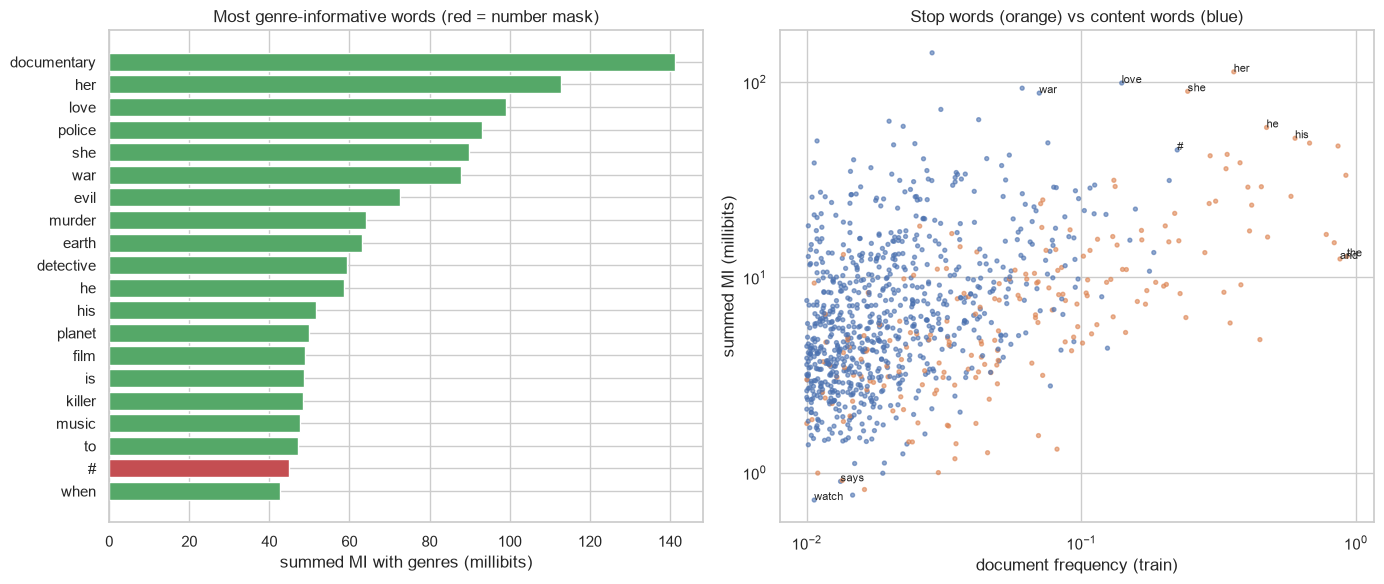

In [9]:
from sklearn.feature_extraction.text import CountVectorizer
def h(p): p = np.clip(p, 1e-9, 1 - 1e-9); return -(p * np.log2(p) + (1 - p) * np.log2(1 - p))
cv = CountVectorizer(token_pattern=r"[\w#][\w#'-]*", binary=True, min_df=0.01)
X = cv.fit_transform([V["detok_num"][i] for i in tr]); Yt = Y[tr].astype(float); n = len(tr)
df = np.asarray(X.sum(0)).ravel(); pw = df / n; c = np.asarray(X.T @ Yt)
mi = 1000 * (h(Yt.mean(0))[None] - (pw[:, None] * h(c / df[:, None]) + (1 - pw[:, None]) * h((Yt.sum(0) - c) / (n - df)[:, None]))).sum(1)
vocab = np.array(cv.get_feature_names_out()); sw = pp.stopword_set()
r = pd.DataFrame({"word": vocab, "doc_freq": pw, "MI_mbit": mi, "stopword": [w in sw for w in vocab]}).sort_values("MI_mbit")
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
top = r.tail(20); ax[0].barh(top.word, top.MI_mbit, color=["#C44E52" if w == "#" else "#55A868" for w in top.word])
ax[0].set_title("Most genre-informative words (red = number mask)"); ax[0].set_xlabel("summed MI with genres (millibits)")
ax[1].scatter(r.doc_freq, r.MI_mbit, s=8, c=np.where(r.stopword, "#DD8452", "#4C72B0"), alpha=.6)
ax[1].set_xscale("log"); ax[1].set_yscale("log"); ax[1].set_xlabel("document frequency (train)"); ax[1].set_ylabel("summed MI (millibits)")
ax[1].set_title("Stop words (orange) vs content words (blue)")
for w in ["the", "and", "his", "her", "she", "he", "#", "love", "war", "watch", "says"]:
    if w in set(r.word): rr = r[r.word == w].iloc[0]; ax[1].annotate(w, (rr.doc_freq, rr.MI_mbit), fontsize=8)
plt.tight_layout()
red = json.load(open(SPLITS / "redundant_words.json"))
print(f"{len(red)} corpus-redundant words (train only), e.g.:", list(red)[:30])
print("stop words with HIGH genre information:", list(r[r.stopword].sort_values("MI_mbit").tail(8).word))

Several stop words are *not* uninformative: the gendered pronouns *he / his / him* and *she / her* rank among the most
genre-informative frequent words (*she* appears 1.7× more often in Romance plots and 7× less often in Documentaries; *he/his* lean Western and Film-Noir), as do *is* and *when*. A generic
stop list removes these too. This is one reason stop-word removal is expected to help a
bag-of-words model (less noise in a sparse space) yet hurt a contextual encoder, which uses those words. §9 tests it.

### 4e. Most distinctive content words per genre (χ²)

In [10]:
from sklearn.feature_selection import chi2
cv2 = CountVectorizer(min_df=20, stop_words="english"); X2 = cv2.fit_transform(V["detok_num"]); voc = np.array(cv2.get_feature_names_out())
rows = {}
for g in ["Horror", "Documentary", "Western", "Romance", "Sci-Fi", "Animation", "War", "Film-Noir"]:
    yk = Y[:, GENRES.index(g)]; c2, _ = chi2(X2, yk)
    over = np.asarray(X2[yk == 1].mean(0)).ravel() > np.asarray(X2.mean(0)).ravel(); c2[~over] = 0
    rows[g] = ", ".join(voc[np.argsort(-c2)[:10]])
pd.DataFrame.from_dict(rows, orient="index", columns=["most distinctive words (χ², over-represented)"])

,"most distinctive words (χ², over-represented)"
Horror,"vampire, dr, zombies, horror, house, vampires,..."
Documentary,"documentary, film, interviews, footage, filmma..."
Western,"cattle, ranch, wagon, gold, rancher, outlaw, i..."
Romance,"love, relationship, meets, married, marry, fal..."
Sci-Fi,"earth, planet, alien, space, scientist, aliens..."
Animation,"animated, superman, batman, dragon, rabbit, an..."
War,"war, german, army, germans, soldiers, nazi, ii..."
Film-Noir,"marlowe, johnny, police, murder, joe, tony, br..."


## 5. Image modality

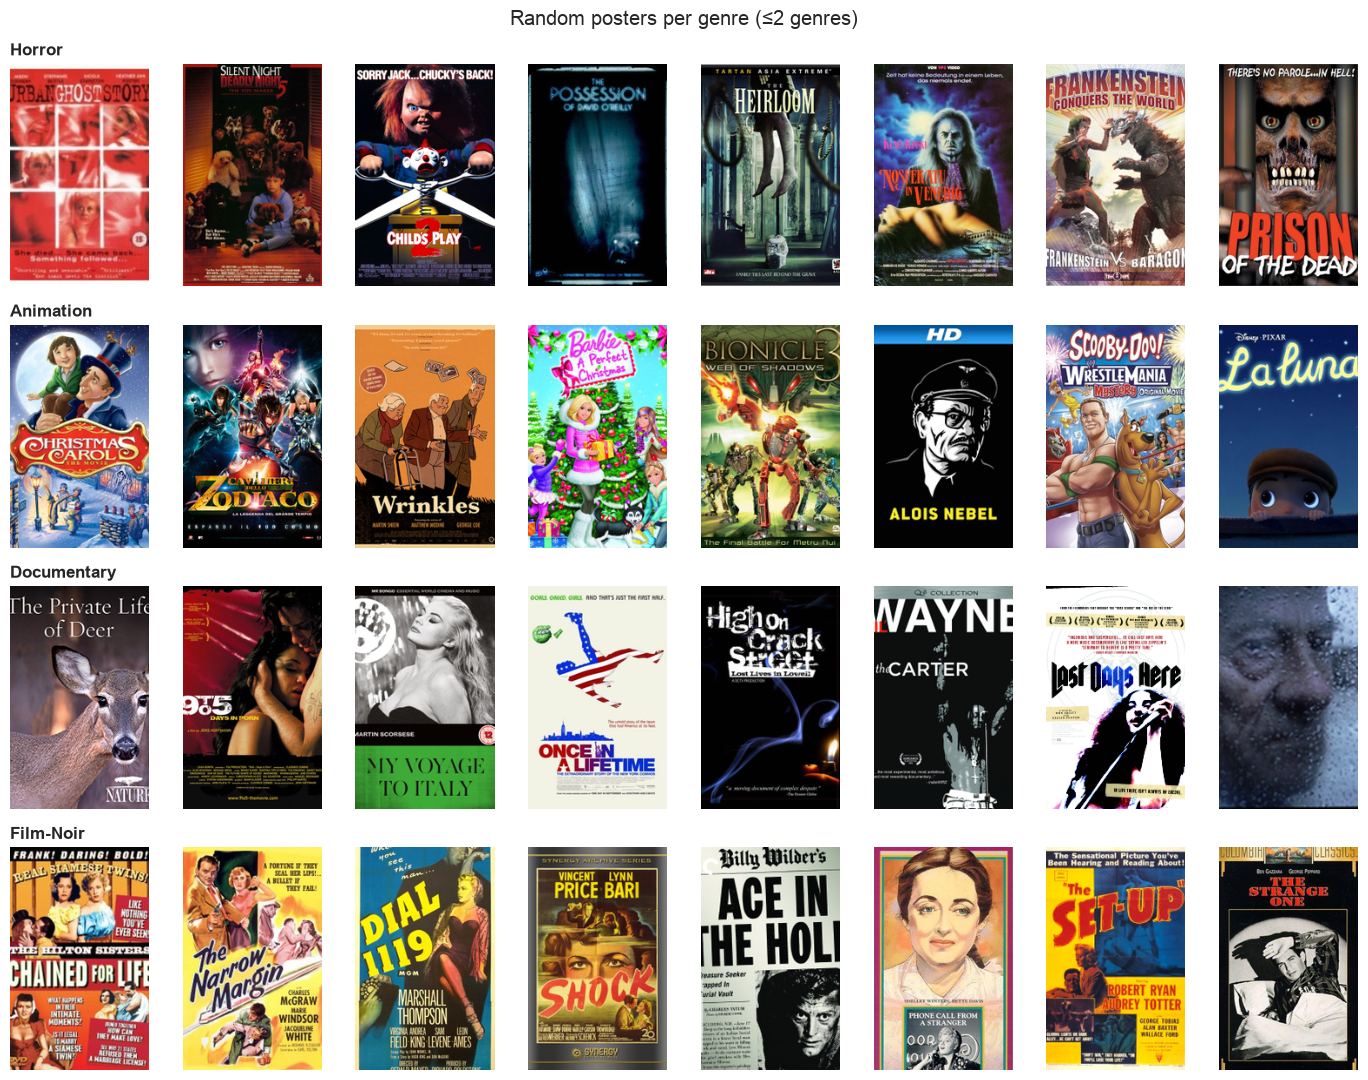

In [11]:
rng = np.random.default_rng(0)
fig, ax = plt.subplots(4, 8, figsize=(14, 11))
for r_, g in enumerate(["Horror", "Animation", "Documentary", "Film-Noir"]):
    ids = rng.choice(np.flatnonzero((Y[:, GENRES.index(g)] == 1) & (Y.sum(1) <= 2)), 8, replace=False)
    for c_, i in enumerate(ids): ax[r_, c_].imshow(decode(np.asarray(mm[i]))); ax[r_, c_].axis("off")
    ax[r_, 0].set_title(g, loc="left", fontsize=12, weight="bold")
plt.suptitle("Random posters per genre (≤2 genres)"); plt.tight_layout()

### 5a. CLIP preprocessing: centre crop (proposal) vs letterbox
CLIP's standard transform resizes the short side to 224 and centre-crops. A 256×160 poster becomes 358×224, so the crop removes
**67 px (≈19%) at the top and bottom**, which is where titles, taglines and credits sit. Letterboxing pads the sides instead and keeps the
whole poster at a lower resolution. §9 compares both on validation.

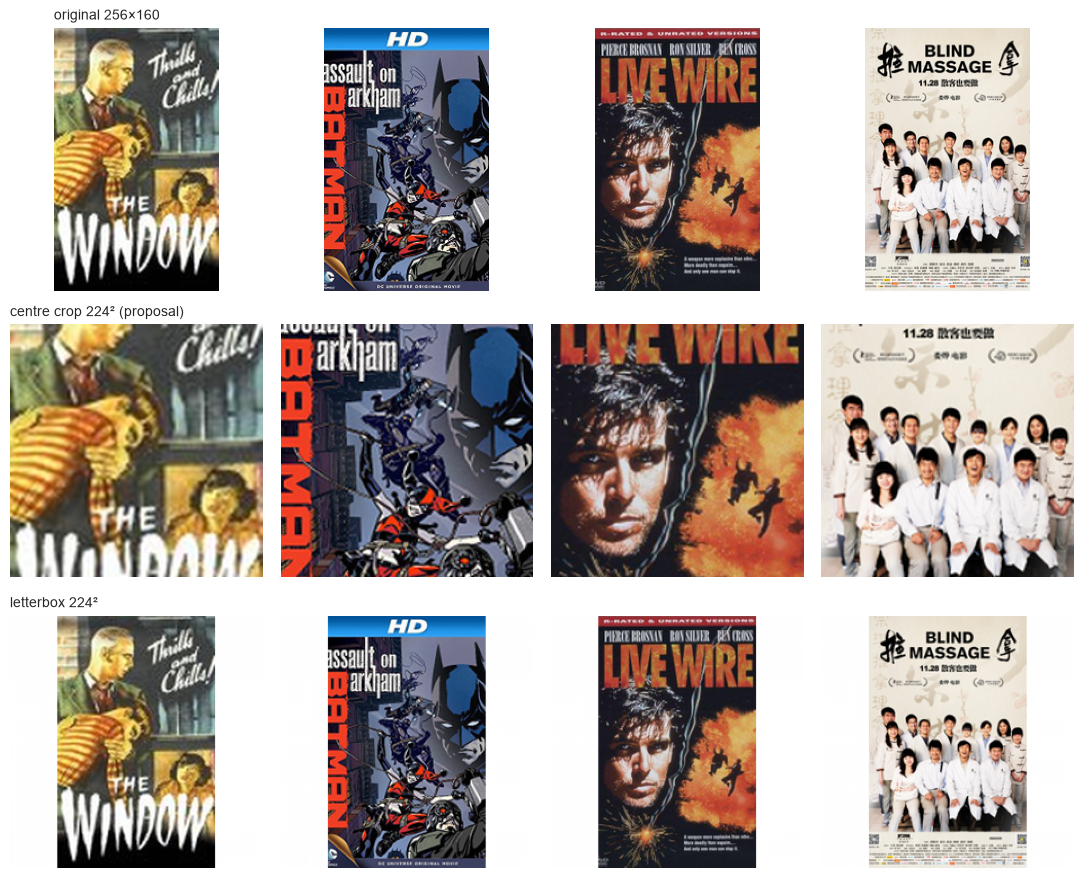

In [12]:
import torch, torch.nn.functional as F
ex = [3, 2050, 9000, 15000]
x = torch.from_numpy(decode(np.asarray(mm[ex]))).permute(0, 3, 1, 2).float() / 255
crop = F.interpolate(x, size=(358, 224), mode="bicubic", antialias=True)[..., 67:291, :]
lbox = F.interpolate(pp.letterbox(x), size=224, mode="bicubic", antialias=True)
fig, ax = plt.subplots(3, 4, figsize=(11, 9))
for k in range(4):
    for r_, (img, t) in enumerate([(x[k], "original 256×160"), (crop[k], "centre crop 224² (proposal)"), (lbox[k], "letterbox 224²")]):
        ax[r_, k].imshow(img.permute(1, 2, 0).clamp(0, 1).numpy()); ax[r_, k].axis("off")
        if k == 0: ax[r_, k].set_title(t, loc="left", fontsize=10)
plt.tight_layout()

grayscale posters: 1,239 (4.8%)
{'Short': 0.146, 'Documentary': 0.095, 'Film-Noir': 0.071, 'Biography': 0.07, 'History': 0.068}


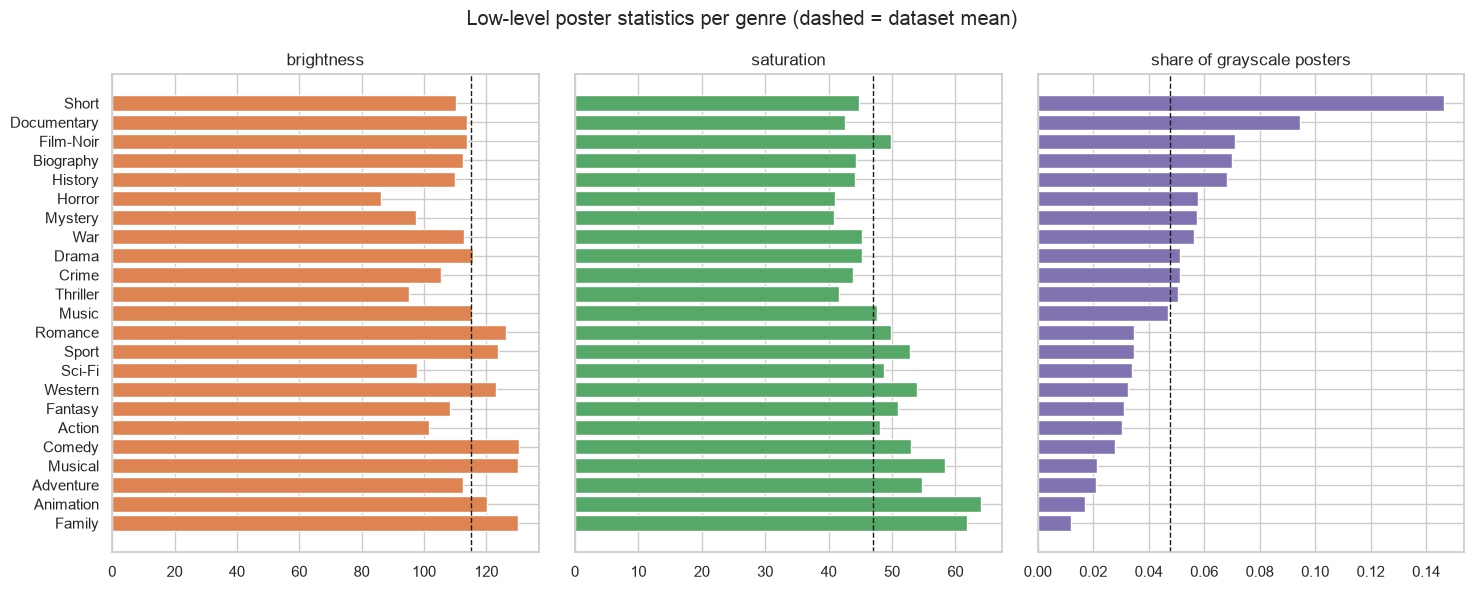

In [13]:
gstat = pd.DataFrame({g: meta.loc[Y[:, k] == 1, ["brightness", "saturation", "grayscale"]].mean() for k, g in enumerate(GENRES)}).T.sort_values("grayscale")
fig, ax = plt.subplots(1, 3, figsize=(15, 6), sharey=True)
for a, col, c in zip(ax, gstat.columns, ["#DD8452", "#55A868", "#8172B2"]):
    a.barh(gstat.index, gstat[col], color=c); a.set_title(col if col != "grayscale" else "share of grayscale posters"); a.axvline(meta[col].mean(), color="k", ls="--", lw=1)
plt.suptitle("Low-level poster statistics per genre (dashed = dataset mean)"); plt.tight_layout()
print(f"grayscale posters: {meta.grayscale.sum():,} ({meta.grayscale.mean():.1%})"); print(gstat.grayscale.sort_values(ascending=False).head(5).round(3).to_dict())

Grayscale posters (4.8%) are 2–3× more common for Short, Documentary, Film-Noir, History and Biography. That is a proxy for
*era and budget*, not genre, and a possible shortcut for the image model, audited in the report's bias section. Horror posters are
the darkest; Family and Animation the most saturated.

## 6. Duplicates and label noise
The proposal's Table A.3 is reproduced exactly by exact hashing (first table below).
We additionally merge **near-duplicate** posters (dHash Hamming ≤ 4, e.g. re-encoded placeholder artwork) with union-find.

,groups,rows,redundant_rows,groups_with_differing_labels
Plot summary,11,25,14,4
Poster image,63,151,88,39
Plot and poster (exact pair),6,12,6,0


{
 "exact_duplicate_poster_groups": 63,
 "rows_in_exact_duplicate_posters": 151,
 "exact_duplicate_plot_groups": 11,
 "rows_in_exact_duplicate_plots": 25,
 "near_duplicate_image_pairs_dhash": 148,
 "duplicate_groups_size_gt1": 79,
 "rows_in_duplicate_groups": 196,
 "label_conflict_rows_excluded": 11,
 "fragments_lt_min_words": 144
}


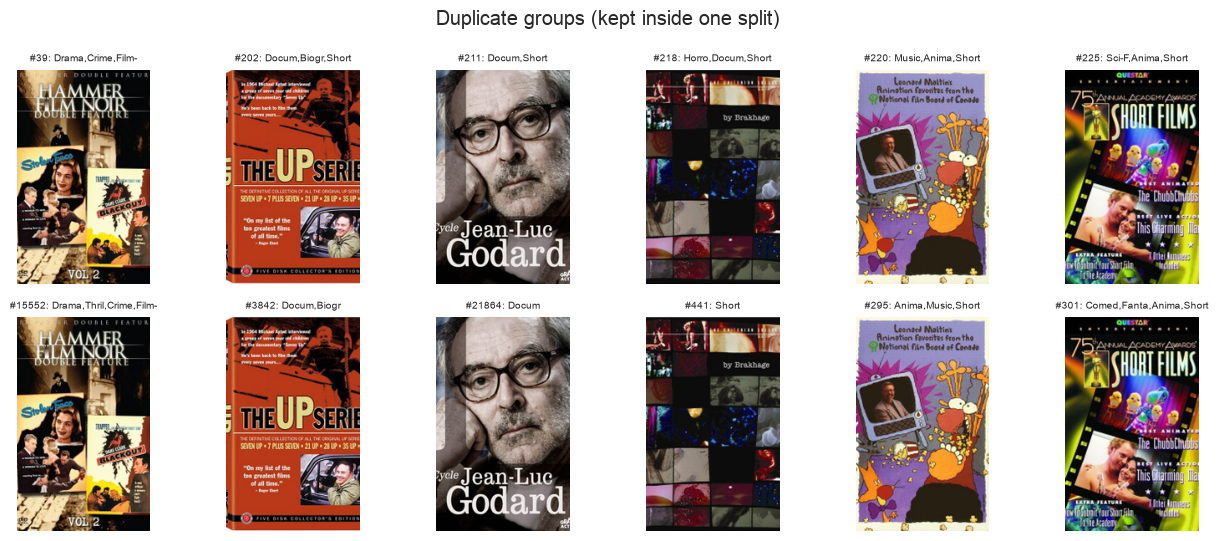

In [14]:
display(pd.DataFrame(S["duplicate_table_A3"]).T.rename(index={"plot_summary": "Plot summary", "poster_image": "Poster image",
        "plot_and_poster": "Plot and poster (exact pair)"}))
print(json.dumps({k: S[k] for k in ["exact_duplicate_poster_groups", "rows_in_exact_duplicate_posters", "exact_duplicate_plot_groups",
      "rows_in_exact_duplicate_plots", "near_duplicate_image_pairs_dhash", "duplicate_groups_size_gt1", "rows_in_duplicate_groups",
      "label_conflict_rows_excluded", "fragments_lt_min_words"]}, indent=1))
g = meta[meta.group.duplicated(keep=False)].groupby("group"); ex = [grp.idx.values[:2] for _, grp in list(g)[:6]]
fig, ax = plt.subplots(2, 6, figsize=(13, 5.5))
for k, (a, b) in enumerate(ex):
    for r_, m_ in enumerate((a, b)):
        ax[r_, k].imshow(decode(np.asarray(mm[m_]))); ax[r_, k].axis("off")
        ax[r_, k].set_title(f"#{m_}: " + ",".join(GENRES[j][:5] for j in np.flatnonzero(Y[m_])), fontsize=7)
plt.suptitle("Duplicate groups (kept inside one split)"); plt.tight_layout()

As in the proposal, 39 duplicate-poster groups have differing labels (generic or placeholder posters), while the 6 exact plot-and-poster pairs agree. The 4 duplicate-plot groups with differing labels contain 11 movies that share a plot but carry contradictory genres. They are label noise and are excluded.

## 7. The fixed 60/10/30 split

{'excluded': 11, 'train': 15569, 'val': 2605, 'test': 7774} {'excluded': 0.0004, 'train': 0.5998, 'val': 0.1004, 'test': 0.2995} | groups crossing splits: 0
min positives per genre: {'train': 202, 'val': 35, 'test': 101}
max abs prevalence difference train vs test: 0.11 pp


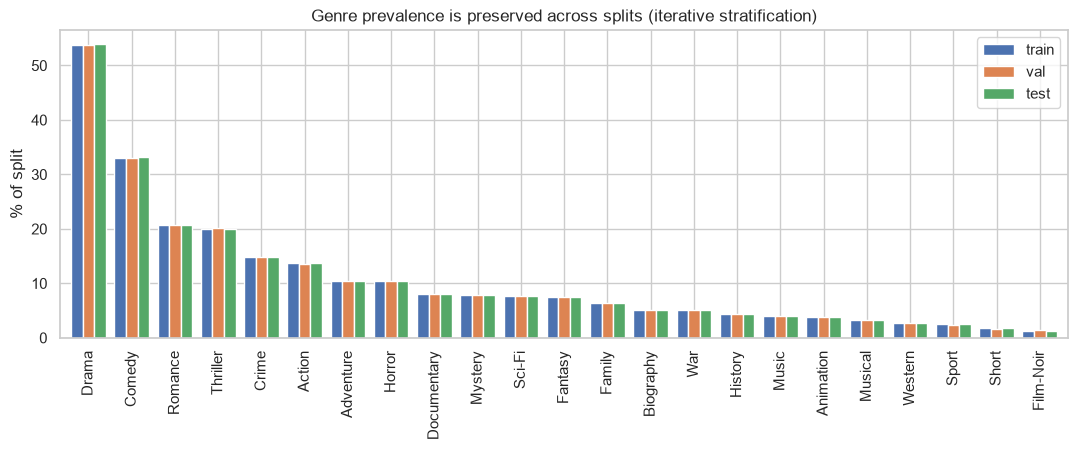

In [15]:
names = {0: "train", 1: "val", 2: "test"}
prev = pd.DataFrame({names[k]: Y[meta.split == k].mean(0) for k in names}, index=GENRES)
print(S["split_sizes"], S["split_shares"], "| groups crossing splits:", S["groups_crossing_splits"])
print("min positives per genre:", S["min_positives_per_genre_by_split"])
ax = (prev * 100).plot.bar(figsize=(13, 4), width=.8); ax.set_ylabel("% of split"); ax.set_title("Genre prevalence is preserved across splits (iterative stratification)")
print("max abs prevalence difference train vs test: %.2f pp" % (100 * (prev.train - prev.test).abs().max()))

The split follows the proposal's 60/10/30 protocol with no duplicate group crossing splits. It is regenerated here, so sizes differ slightly from the
proposal's Table B.1 (15,581 / 2,595 / 7,783): near-duplicate posters are grouped too, and 11 label-conflict movies are excluded. If the group's split file is
placed at `data/shared_split.csv`, `01_preprocess.py` uses it unchanged. Validation is small (2,605 movies, ≥35 positives for the rarest genre),
so validation-tuned thresholds for rare genres are noisy. We report seed variation and bootstrap intervals with that in mind.

## 8. Cross-modal alignment: do poster and plot describe the same film?
Row alignment (§1) does not prove content alignment. Using CLIP (trained to match images to text), the matched poster–plot cosine
should exceed that of random pairs, and retrieval of the correct plot from its poster should be far above chance.

mean cosine matched 0.245 vs random 0.192; matched > random for 85.3% of movies
poster→plot retrieval among 1,000: R@1 17.7%, R@10 33.7% (chance 0.1% / 1%), median rank 43


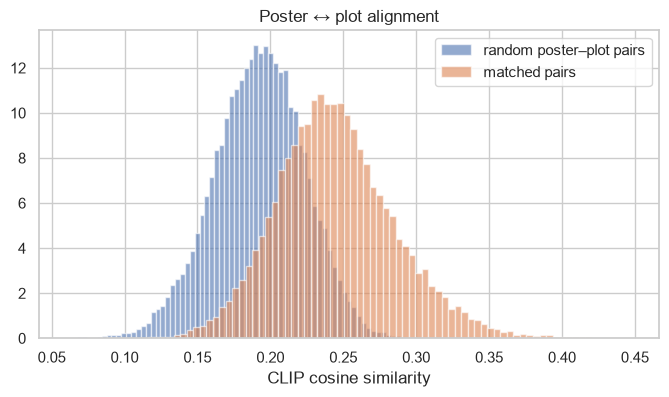

In [16]:
CH = json.load(open(SPLITS / "choices.json")); prep = CH["clip_img_prep"]
EI = np.load(FEAT / f"clip_img_{prep}.npy").astype(np.float32); ET = np.load(FEAT / f"clip_txt_{CH['distil_variant']}.npy").astype(np.float32)
EI /= np.linalg.norm(EI, axis=1, keepdims=True); ET /= np.linalg.norm(ET, axis=1, keepdims=True)
pos = (EI * ET).sum(1); neg = (EI * ET[np.random.default_rng(0).permutation(N)]).sum(1)
sub = np.random.default_rng(1).choice(N, 1000, replace=False); sim = EI[sub] @ ET[sub].T; rank = (sim > np.diag(sim)[:, None]).sum(1)
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(neg, 80, alpha=.6, density=True, label="random poster–plot pairs"); ax.hist(pos, 80, alpha=.6, density=True, label="matched pairs")
ax.set_xlabel("CLIP cosine similarity"); ax.legend(); ax.set_title("Poster ↔ plot alignment")
print(f"mean cosine matched {pos.mean():.3f} vs random {neg.mean():.3f}; matched > random for {(pos > neg).mean():.1%} of movies")
print(f"poster→plot retrieval among 1,000: R@1 {(rank < 1).mean():.1%}, R@10 {(rank < 10).mean():.1%} (chance 0.1% / 1%), median rank {np.median(rank) + 1:.0f}")

Matched pairs are clearly more similar than random pairs and retrieval is far above chance, so the pairing is genuine. The overlap
of the two histograms also shows that many posters say little about the specific plot, which caps what fusion can add.

## 9. Preprocessing ablation (validation decides)
`scripts/03_ablation.py` trains each text variant with TF-IDF + logistic regression and with DistilBERT (+ MLP head, 3 seeds),
and the CLIP poster MLP on crop vs letterbox. **Choices use validation macro-F1 only**; test numbers are shown for transparency.

In [17]:
AB = json.load(open(RESULTS / "ablation.json"))
def tab(d):
    return pd.DataFrame({k: {"val macro-F1": v["val"]["macro_F1"], "val mAP": v["val"]["mAP"], "test macro-F1": v["test"]["macro_F1"],
                             "test mAP": v["test"]["mAP"], "sd (seeds)": v["val"].get("macro_F1_sd", 0)} for k, v in d.items()}).T.round(4)
print("TF-IDF + logistic regression"); display(tab(AB["text_tfidf"]))
print("DistilBERT (variant | pooling) + MLP, mean of 3 seeds"); display(tab(AB["text_distil"]))
print("CLIP poster MLP"); display(tab(AB["image_clip"]))
print("chosen:", CH)

TF-IDF + logistic regression


,val macro-F1,val mAP,test macro-F1,test mAP,sd (seeds)
raw,0.5643,0.5459,0.5423,0.5476,0.0
detok,0.5589,0.5434,0.5366,0.5436,0.0
detok_num,0.5587,0.5433,0.5385,0.5438,0.0
detok_num_stop,0.5599,0.5481,0.5418,0.5481,0.0
detok_num_stop_domain,0.5586,0.5456,0.5408,0.5474,0.0


DistilBERT (variant | pooling) + MLP, mean of 3 seeds


,val macro-F1,val mAP,test macro-F1,test mAP,sd (seeds)
raw|cls,0.5962,0.6016,0.5810,0.6092,0.0019
raw|mean,0.6004,0.6104,0.5894,0.6190,0.0018
detok|cls,0.5923,0.6004,0.5794,0.6096,0.0008
detok|mean,0.6010,0.6096,0.5906,0.6182,0.0009
detok_num|cls,0.5961,0.6019,0.5813,0.6096,0.0020
detok_num|mean,0.6017,0.6088,0.5884,0.6192,0.0020
detok_num_stop|cls,0.5822,0.5869,0.5675,0.5934,0.0006
detok_num_stop|mean,0.5860,0.5894,0.5749,0.5998,0.0008
detok_num_stop_domain|cls,0.5819,0.5860,0.5661,0.5926,0.0016
detok_num_stop_domain|mean,0.5859,0.5878,0.5741,0.6007,0.0008


CLIP poster MLP


,val macro-F1,val mAP,test macro-F1,test mAP,sd (seeds)
crop,0.5119,0.5056,0.4915,0.4897,0.0014
lbox,0.5021,0.4891,0.4723,0.4692,0.0022


chosen: {'tfidf_variant': 'raw', 'distil_variant': 'detok_num', 'distil_pool': 'mean', 'clip_img_prep': 'crop', 'rule': 'max validation macro-F1 (rounded to 3 dp), tie-break validation mAP'}


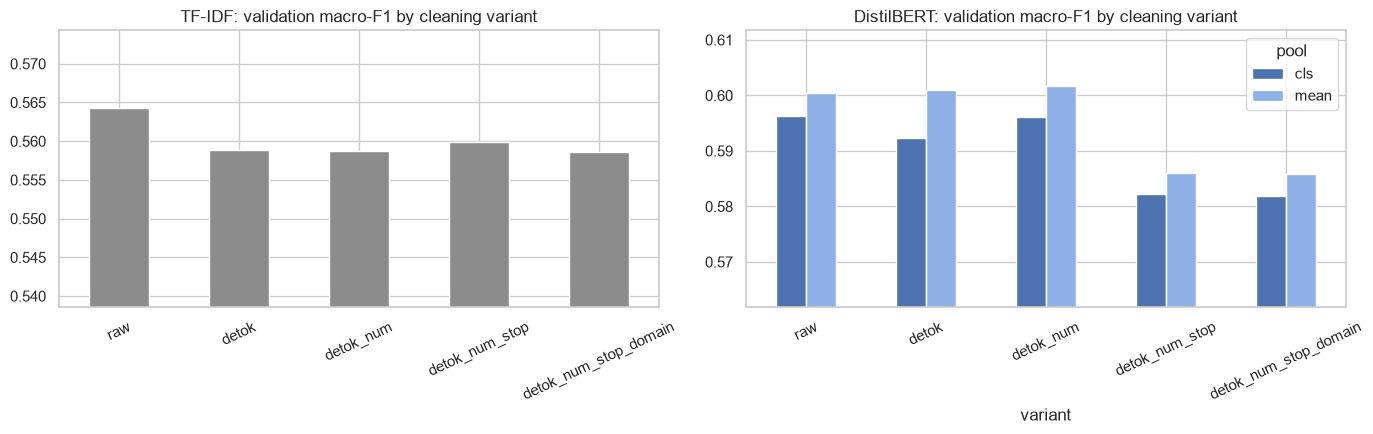

In [18]:
td = tab(AB["text_distil"]); tt = tab(AB["text_tfidf"])
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
tt["val macro-F1"].plot.bar(ax=ax[0], color="#8C8C8C"); ax[0].set_title("TF-IDF: validation macro-F1 by cleaning variant")
ax[0].set_ylim(tt["val macro-F1"].min() - .02, tt["val macro-F1"].max() + .01)
piv = td["val macro-F1"].rename(lambda s: s).to_frame(); piv["variant"] = [k.split("|")[0] for k in piv.index]; piv["pool"] = [k.split("|")[1] for k in piv.index]
piv.pivot(index="variant", columns="pool", values="val macro-F1").loc[TEXT_VARIANTS].plot.bar(ax=ax[1], color=["#4C72B0", "#8FB0E6"])
ax[1].set_title("DistilBERT: validation macro-F1 by cleaning variant"); ax[1].set_ylim(td["val macro-F1"].min() - .02, td["val macro-F1"].max() + .01)
for a in ax: a.tick_params(axis="x", rotation=25)
plt.tight_layout()

## 10. Do the modalities carry complementary signal?

genres where the poster beats the plot: ['Comedy', 'Family', 'Animation', 'Musical', 'Film-Noir']


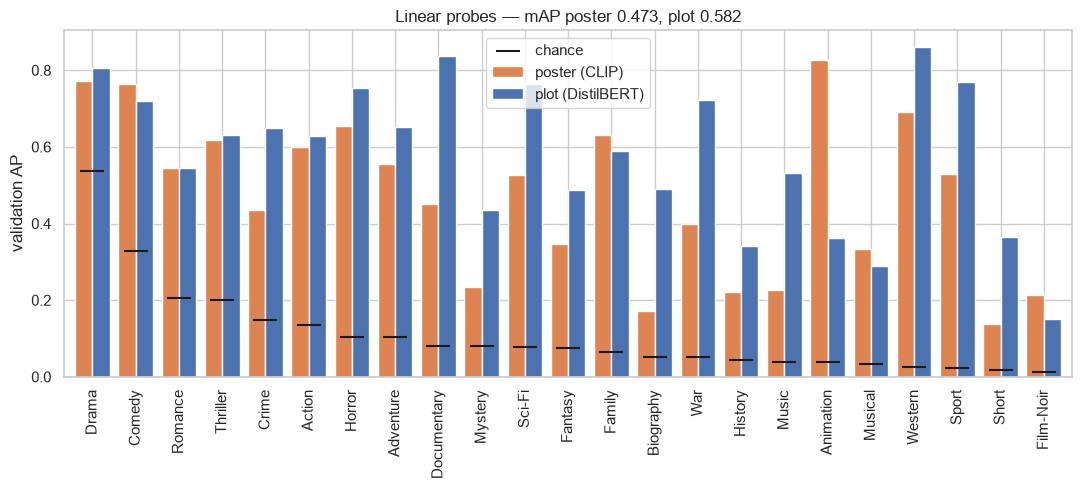

In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import average_precision_score
def probe(X):
    X = X.astype(np.float32); X = (X - X[tr].mean(0)) / (X[tr].std(0) + 1e-6)
    c = OneVsRestClassifier(LogisticRegression(C=0.05, max_iter=2000), n_jobs=-1).fit(X[tr], Y[tr]); P = c.predict_proba(X[va])
    return np.array([average_precision_score(Y[va, k], P[:, k]) for k in range(23)])
api = probe(np.load(FEAT / f"clip_img_{prep}.npy")); apt = probe(np.load(FEAT / f"txt_distil_{CH['distil_variant']}_{CH['distil_pool']}.npy"))
d = pd.DataFrame({"poster (CLIP)": api, "plot (DistilBERT)": apt, "prevalence": Y[va].mean(0)}, index=GENRES).sort_values("prevalence", ascending=False)
ax = d[["poster (CLIP)", "plot (DistilBERT)"]].plot.bar(figsize=(13, 4.5), width=.8, color=["#DD8452", "#4C72B0"])
ax.scatter(range(23), d.prevalence, marker="_", s=300, c="k", zorder=5, label="chance"); ax.legend(); ax.set_ylabel("validation AP")
ax.set_title(f"Linear probes — mAP poster {api.mean():.3f}, plot {apt.mean():.3f}")
print("genres where the poster beats the plot:", list(d.index[d["poster (CLIP)"] > d["plot (DistilBERT)"]]))

With CLIP features the poster is a strong modality in its own right and **wins outright on visually defined genres**, while the plot
wins on narrative and factual genres. Complementary errors are the precondition for fusion to help.

## Summary: data-quality issues → preprocessing decisions
| Issue found | Evidence | Mitigation (where) |
|---|---|---|
| Posters stored as mean-subtracted BGR with uint8 wrap-around | §2 | `data.decode()` |
| Genre order not shipped | §1 | recovered from Arevalo et al. (2017), 23/23 match |
| 41× label imbalance | §3 | iterative stratification, macro-F1, per-genre thresholds |
| Pre-tokenised text, split punctuation | §4b | `detok()` |
| Numbers pre-masked as `N`; `(N)` year asides | §4b, §4d | `mask_numbers()`: drop year asides, `N`→`#`, mask kept (informative) |
| Stop words / corpus-redundant words | §4c–d, §9 | variants compared on validation; choice per model family |
| 10% of plots exceed 256 tokens | §4a | stop-word variant tested; BERT-512 compared in the report |
| Centre crop removes title/credit bands | §5a, §9 | crop vs letterbox compared on validation |
| Grayscale ⇔ factual/old genres | §5 | subgroup audit in the report |
| 63 duplicate-poster / 11 duplicate-plot groups (+ near duplicates) | §6 | grouped split, 0 groups cross |
| Contradictory labels on identical plots | §6 | 11 rows excluded |
| Content alignment of modalities | §8 | verified with CLIP retrieval |